In [1]:
from langchain.chat_models import init_chat_model




# openrouter model for subagents 
openrouter_model = init_chat_model(
    "openrouter:meta-llama/llama-3.3-70b-instruct"
)

# groq model for deepagents
groq_model = init_chat_model(
    "groq:openai/gpt-oss-20b"
)

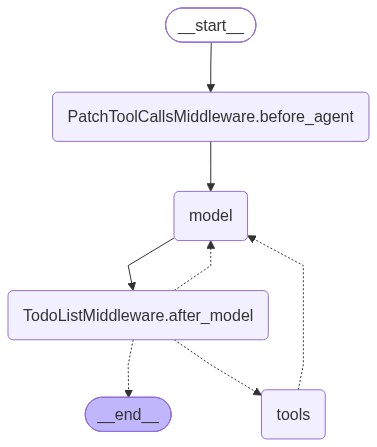

In [2]:
from langchain.tools import tool
from langchain.agents.middleware import TodoListMiddleware
from langchain_tavily import TavilySearch
from langchain.agents import create_agent

from deepagents import CompiledSubAgent, create_deep_agent
from deepagents.backends import StateBackend

from langgraph.checkpoint.memory import InMemorySaver
from typing import Dict, Any 

@tool
def web_search(query: str, max_results: int = 1,include_answer: bool = True, include_raw_content: bool = False)->Dict[str, Any]:
    """
    A Web searching tool
    returns a dictonary of results
    """
    tool = TavilySearch(
        max_results=max_results,
        topic="general",
        include_answer=include_answer,
        include_raw_content=include_raw_content,
        search_depth="basic",
    )
    return tool.invoke(query)

# create_agent returs a compiled graph
custom_graph = create_agent(
    model = openrouter_model,
    system_prompt="You are a data analysis specialist. Use available tools when necessary.",
    tools=[web_search]
)


# wrap the compiled graph to assign its name, description and runnable graph anf communication between subagents and deepagents
subagent = CompiledSubAgent(
    name="data-analyzer",
    description="MANDATORY for any market research, pricing metrics, cost lookups, or competitive analysis tasks. Analyzes numerical data, performs calculations",
    runnable=custom_graph
)


# register with create_deepagent
deepagent = create_deep_agent(
    model=groq_model,
    backend=StateBackend(),
    checkpointer=InMemorySaver(),
    subagents=[subagent],
    middleware=[TodoListMiddleware()],
    system_prompt=(
        "You are a strict task coordinator. You possess no internal research capabilities.\n\n"
        "WORKFLOW RULES:\n"
        "1. BEFORE doing anything else, you MUST use the `write_todos` tool to write out a todo list for the user's request.\n"
        "2. For any request regarding market analysis, costs, or domain research, you MUST call the `task()` tool with subagent_type='data-analyzer'.\n"
        "3. Once the subagent tool returns a result, update the todo item to completed using `write_todos` and relay the EXACT response directly to the user without adding supplementary figures."
    )
)  
deepagent

In [3]:
resp = deepagent.invoke({
    'messages': "Reserach about LLM Gateways and provide me a detailed summary."
},config={
    "configurable":{
        "thread_id": "sub-1"
        
    }
}
)

In [5]:
for m in resp["messages"]:
    m.pretty_print()

================================ Human Message =================================

Reserach about LLM Gateways and provide me a detailed summary.
================================== Ai Message ==================================
Tool Calls:
  write_todos (fc_cc3a019f-5ddd-421a-80b7-025b70eab186)
 Call ID: fc_cc3a019f-5ddd-421a-80b7-025b70eab186
  Args:
    todos: [{'content': 'Research LLM Gateways and summarize', 'status': 'in_progress'}]
================================= Tool Message =================================
Name: write_todos

Updated todo list to [{'content': 'Research LLM Gateways and summarize', 'status': 'in_progress'}]
================================== Ai Message ==================================
Tool Calls:
  task (fc_4bbb6d3e-f1c4-4122-9d45-63340fbb0e3b)
 Call ID: fc_4bbb6d3e-f1c4-4122-9d45-63340fbb0e3b
  Args:
    description: Research LLM Gateways and provide a detailed summary. The summary should cover what LLM gateways are, their purpose, typical features, key prov

In [ ]:
# Test the worker independently
worker_result = custom_graph.invoke({
    "messages": [
        {
            "role": "user",
            "content": (
                "Research LLM Gateways. "
                "Explain their architecture, benefits, "
                "limitations and popular implementations."
            )
        }
    ]
})

# Inspect the actual messages
for message in worker_result["messages"]:
    print("\nType:", type(message).__name__)
    print("Content:", message.content)